In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/ishaans23/cbis-ddsm-training/shared_mass_calc_audit.csv
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/image_metadata.csv
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/excluded_mass_cases.csv
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/cache_info.json
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/splits/val.csv
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/splits/split_summary.csv
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/splits/patient_split.csv
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/splits/all_with_split.csv
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/splits/train.csv
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/splits/test.csv
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/npy/P_00187_LEFT_MLO.npy
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/npy/P_01047_LEFT_CC.npy
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/npy/P_00856_LEFT_MLO.npy
/kaggle/input/datasets/ishaans23/cbis-dd

In [1]:
from pathlib import Path

import json
import random

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

In [3]:
SEED = 42

TARGET_HEIGHT = 1024
TARGET_WIDTH = 640

random.seed(SEED)
np.random.seed(SEED)

OUTPUT_DIR = Path(
    "/kaggle/working/segmentation_audit"
)

FIGURE_DIR = OUTPUT_DIR / "figures"

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("Output:", OUTPUT_DIR)

Output: /kaggle/working/segmentation_audit


In [4]:
KAGGLE_INPUT_ROOT = Path(
    "/kaggle/input"
)

dataset_candidates = []

for cache_info_path in KAGGLE_INPUT_ROOT.rglob(
    "cache_info.json"
):
    candidate_root = (
        cache_info_path.parent
    )

    required_paths = [
        candidate_root / "npy",
        candidate_root / "masks",
        candidate_root / "splits",
    ]

    if all(
        path.exists()
        for path in required_paths
    ):
        dataset_candidates.append(
            candidate_root
        )


assert len(dataset_candidates) > 0, (
    "Could not locate model-ready CBIS-DDSM dataset."
)

dataset_candidates = sorted(
    dataset_candidates,
    key=lambda path: len(str(path)),
)

PROJECT_ROOT = (
    dataset_candidates[0]
)

print("Dataset:")
print(PROJECT_ROOT)

Dataset:
/kaggle/input/datasets/ishaans23/cbis-ddsm-training


In [5]:
SPLITS_DIR = (
    PROJECT_ROOT / "splits"
)

train_df = pd.read_csv(
    SPLITS_DIR / "train.csv"
)

val_df = pd.read_csv(
    SPLITS_DIR / "val.csv"
)

test_df = pd.read_csv(
    SPLITS_DIR / "test.csv"
)

all_df = pd.concat(
    [
        train_df,
        val_df,
        test_df,
    ],
    ignore_index=True,
)


print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Total:", len(all_df))

print(
    "\nAbnormality types:"
)

print(
    all_df[
        "abnormality_type"
    ].value_counts(
        dropna=False
    )
)

Train: 1885
Validation: 408
Test: 394
Total: 2687

Abnormality types:
abnormality_type
calcification         1458
mass                  1176
mass+calcification      53
Name: count, dtype: int64


In [6]:
audit_rows = []


for row in tqdm(
    all_df.itertuples(index=False),
    total=len(all_df),
    desc="Auditing image-mask pairs",
):

    image_path = (
        PROJECT_ROOT
        / row.npy_path
    )

    mask_path = (
        PROJECT_ROOT
        / row.mask_path
    )


    image_exists = (
        image_path.exists()
    )

    mask_exists = (
        mask_path.exists()
    )


    image_shape = None
    mask_shape = None

    image_dtype = None
    mask_dtype = None

    mask_pixels = None
    mask_fraction = None

    mask_binary = False


    if image_exists:

        image = np.load(
            image_path,
            mmap_mode="r",
        )

        image_shape = (
            tuple(image.shape)
        )

        image_dtype = str(
            image.dtype
        )


    if mask_exists:

        mask = cv2.imread(
            str(mask_path),
            cv2.IMREAD_GRAYSCALE,
        )

        if mask is not None:

            mask_shape = (
                tuple(mask.shape)
            )

            mask_dtype = str(
                mask.dtype
            )

            unique_values = (
                np.unique(mask)
            )

            mask_binary = (
                set(
                    unique_values.tolist()
                )
                .issubset(
                    {0, 255}
                )
            )

            mask_pixels = int(
                np.count_nonzero(mask)
            )

            mask_fraction = (
                mask_pixels
                / mask.size
            )


    audit_rows.append(
        {
            "image_key": row.image_key,
            "patient_id": row.patient_id,
            "split": row.split,
            "abnormality_type": (
                row.abnormality_type
            ),
            "pathology": row.pathology,

            "image_exists": image_exists,
            "mask_exists": mask_exists,

            "image_shape": image_shape,
            "mask_shape": mask_shape,

            "image_dtype": image_dtype,
            "mask_dtype": mask_dtype,

            "mask_binary": mask_binary,

            "mask_pixels": mask_pixels,
            "mask_fraction": mask_fraction,
        }
    )


audit_df = pd.DataFrame(
    audit_rows
)


audit_df.to_csv(
    OUTPUT_DIR
    / "segmentation_pair_audit.csv",
    index=False,
)


print(
    "Image files missing:",
    (~audit_df["image_exists"]).sum(),
)

print(
    "Mask files missing:",
    (~audit_df["mask_exists"]).sum(),
)

print(
    "Non-binary masks:",
    (~audit_df["mask_binary"]).sum(),
)

print(
    "Empty masks:",
    (
        audit_df["mask_pixels"]
        == 0
    ).sum(),
)

Auditing image-mask pairs:   0%|          | 0/2687 [00:00<?, ?it/s]

Image files missing: 0
Mask files missing: 0
Non-binary masks: 0
Empty masks: 0


In [7]:
expected_shape = (
    TARGET_HEIGHT,
    TARGET_WIDTH,
)

image_shape_ok = (
    audit_df[
        "image_shape"
    ]
    == str(expected_shape)
)

mask_shape_ok = (
    audit_df[
        "mask_shape"
    ]
    == str(expected_shape)
)


# Tuple columns may remain actual tuples
image_shape_ok = audit_df[
    "image_shape"
].apply(
    lambda x:
        x == expected_shape
)

mask_shape_ok = audit_df[
    "mask_shape"
].apply(
    lambda x:
        x == expected_shape
)


print(
    "Incorrect image shapes:",
    (~image_shape_ok).sum(),
)

print(
    "Incorrect mask shapes:",
    (~mask_shape_ok).sum(),
)


assert image_shape_ok.all(), (
    "Some cached mammograms do not have "
    "the expected geometry."
)

assert mask_shape_ok.all(), (
    "Some cached masks do not have "
    "the expected geometry."
)

print(
    "\nAll image-mask pairs are "
    "1024 × 640."
)

Incorrect image shapes: 0
Incorrect mask shapes: 0

All image-mask pairs are 1024 × 640.


In [8]:
mask_stats = (
    audit_df[
        "mask_fraction"
    ]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
        ]
    )
)

print(
    "Mask fraction statistics:"
)

display(mask_stats)


print(
    "\nMedian lesion percentage:"
)

print(
    f"{audit_df['mask_fraction'].median() * 100:.4f}%"
)


print(
    "\nSmallest masks:"
)

display(
    audit_df[
        [
            "image_key",
            "abnormality_type",
            "mask_pixels",
            "mask_fraction",
        ]
    ]
    .sort_values(
        "mask_pixels"
    )
    .head(10)
)

Mask fraction statistics:


count    2687.000000
mean        0.015375
std         0.038372
min         0.000114
1%          0.000308
5%          0.000768
10%         0.001216
25%         0.002398
50%         0.005206
75%         0.012663
90%         0.032112
95%         0.055731
99%         0.192340
max         0.583426
Name: mask_fraction, dtype: float64


Median lesion percentage:
0.5206%

Smallest masks:


,image_key,abnormality_type,mask_pixels,mask_fraction
1649,P_01740_LEFT_CC,calcification,75,0.000114
1650,P_01740_LEFT_MLO,calcification,76,0.000116
414,P_00476_LEFT_CC,calcification,76,0.000116
218,P_00250_LEFT_MLO,calcification,78,0.000119
2051,P_00750_LEFT_CC,calcification,93,0.000142
2052,P_00750_LEFT_MLO,calcification,99,0.000151
865,P_00916_RIGHT_MLO,calcification,109,0.000166
2308,P_00092_RIGHT_CC,mass,118,0.000180
1146,P_01211_LEFT_CC,calcification,122,0.000186
1267,P_01336_LEFT_CC,calcification,131,0.000200


In [9]:
mask_type_summary = (
    audit_df
    .groupby(
        "abnormality_type"
    )
    .agg(
        samples=(
            "image_key",
            "count",
        ),
        median_mask_pixels=(
            "mask_pixels",
            "median",
        ),
        mean_mask_pixels=(
            "mask_pixels",
            "mean",
        ),
        median_mask_fraction=(
            "mask_fraction",
            "median",
        ),
        mean_mask_fraction=(
            "mask_fraction",
            "mean",
        ),
    )
    .reset_index()
)


mask_type_summary[
    "median_mask_percent"
] = (
    mask_type_summary[
        "median_mask_fraction"
    ]
    * 100
)


mask_type_summary[
    "mean_mask_percent"
] = (
    mask_type_summary[
        "mean_mask_fraction"
    ]
    * 100
)


display(
    mask_type_summary
)


mask_type_summary.to_csv(
    OUTPUT_DIR
    / "mask_statistics_by_abnormality.csv",
    index=False,
)

,abnormality_type,samples,median_mask_pixels,mean_mask_pixels,median_mask_fraction,mean_mask_fraction,median_mask_percent,mean_mask_percent
0,calcification,1458,4246.0,14222.183128,0.006479,0.021701,0.647888,2.170133
1,mass,1176,2919.0,4625.989796,0.004454,0.007059,0.445404,0.705870
2,mass+calcification,53,8548.0,16961.471698,0.013043,0.025881,1.304321,2.588115


In [10]:
def show_image_mask_pair(
    row,
    root_dir,
):

    image = np.load(
        root_dir
        / row["npy_path"]
    )

    mask = cv2.imread(
        str(
            root_dir
            / row["mask_path"]
        ),
        cv2.IMREAD_GRAYSCALE,
    )

    mask_binary = (
        mask > 0
    )


    fig, axes = plt.subplots(
        1,
        3,
        figsize=(15, 7),
    )


    axes[0].imshow(
        image,
        cmap="gray",
    )

    axes[0].set_title(
        "Mammogram"
    )


    axes[1].imshow(
        mask_binary,
        cmap="gray",
    )

    axes[1].set_title(
        "Ground-Truth Mask"
    )


    axes[2].imshow(
        image,
        cmap="gray",
    )

    axes[2].imshow(
        mask_binary,
        alpha=0.4,
    )

    axes[2].set_title(
        "Mask Overlay"
    )


    for ax in axes:
        ax.axis("off")


    fig.suptitle(
        f"{row['image_key']} | "
        f"{row['abnormality_type']} | "
        f"{row['pathology']}",
        fontsize=14,
    )


    plt.tight_layout()

    plt.show()

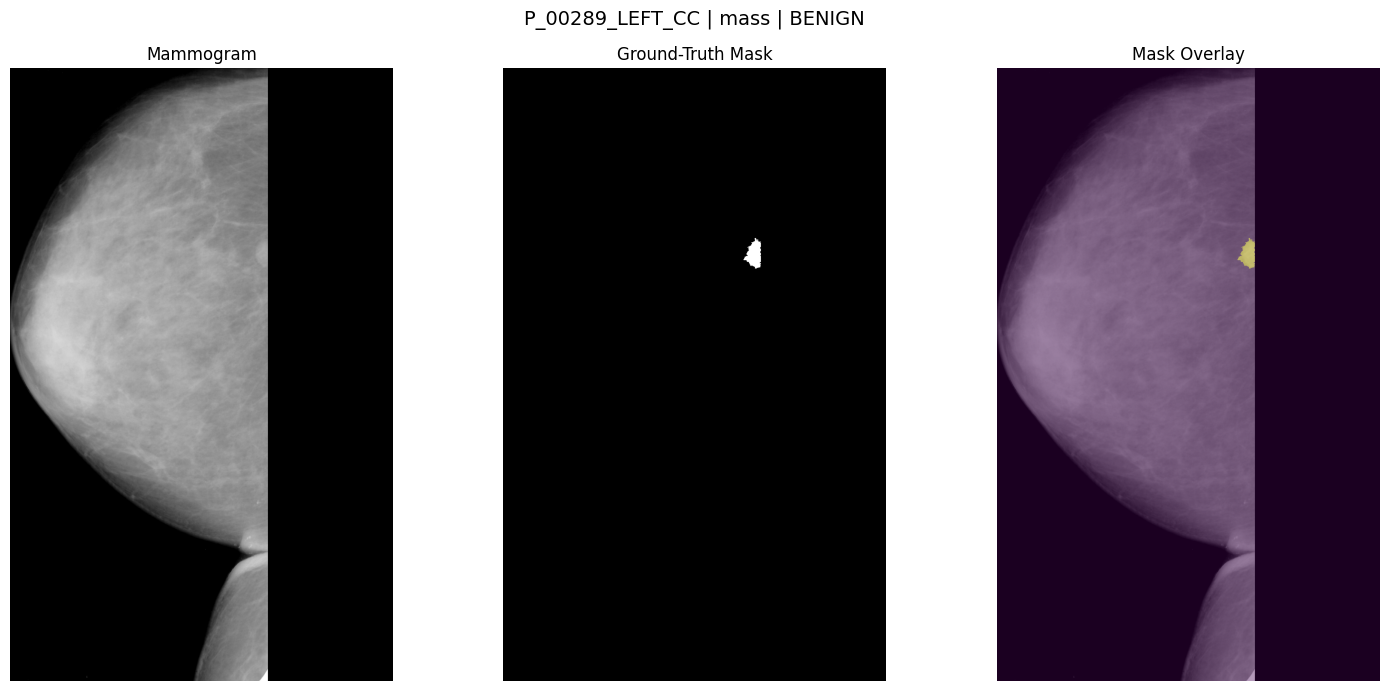

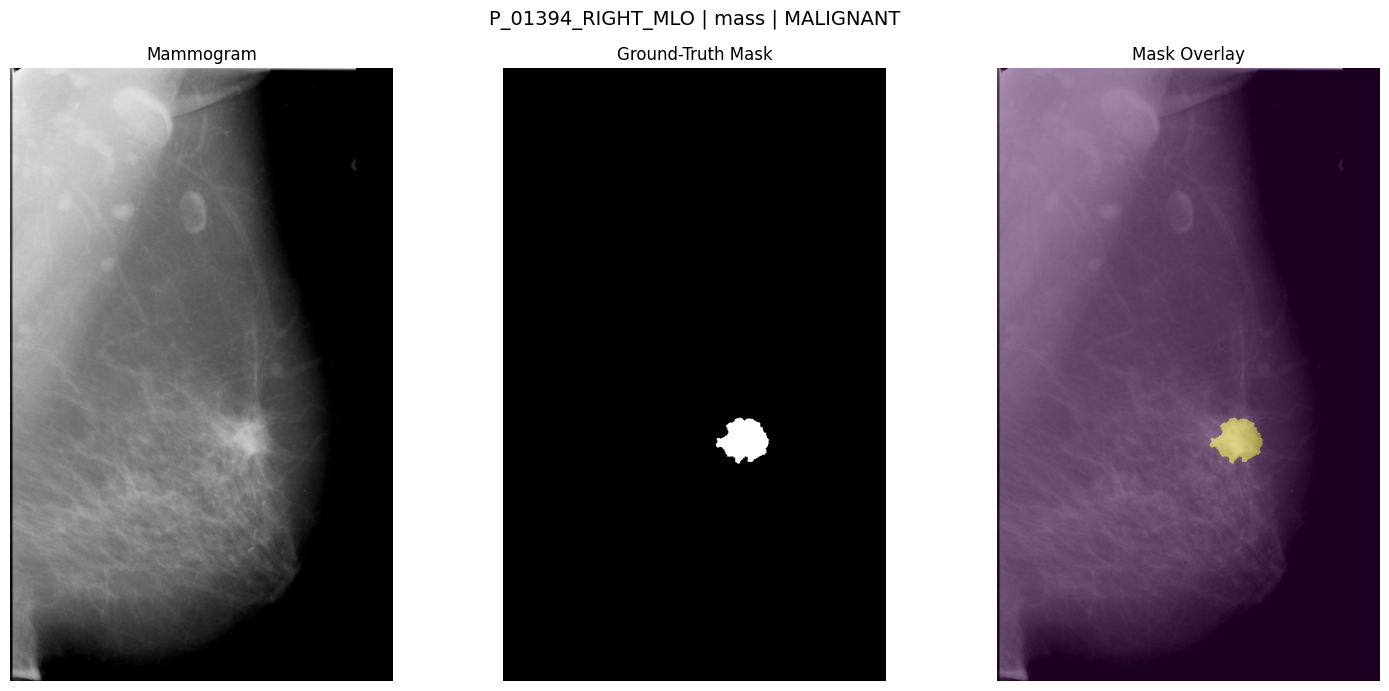

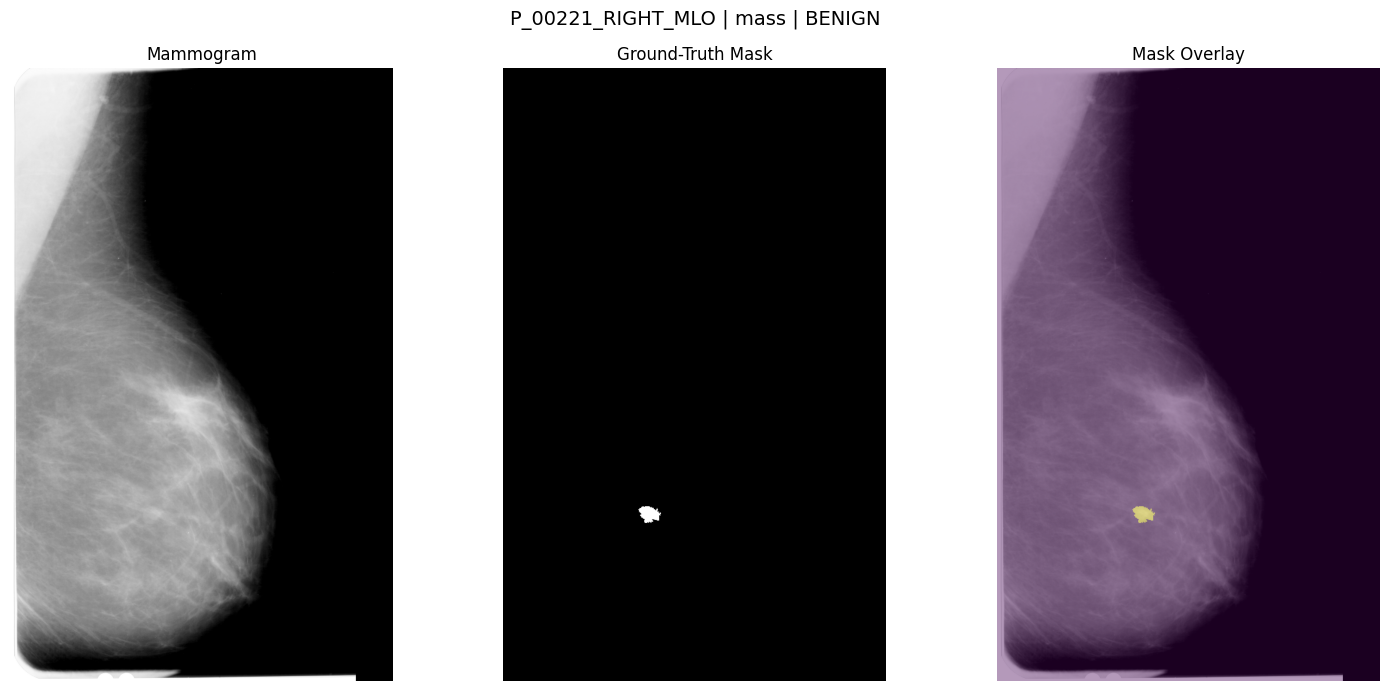

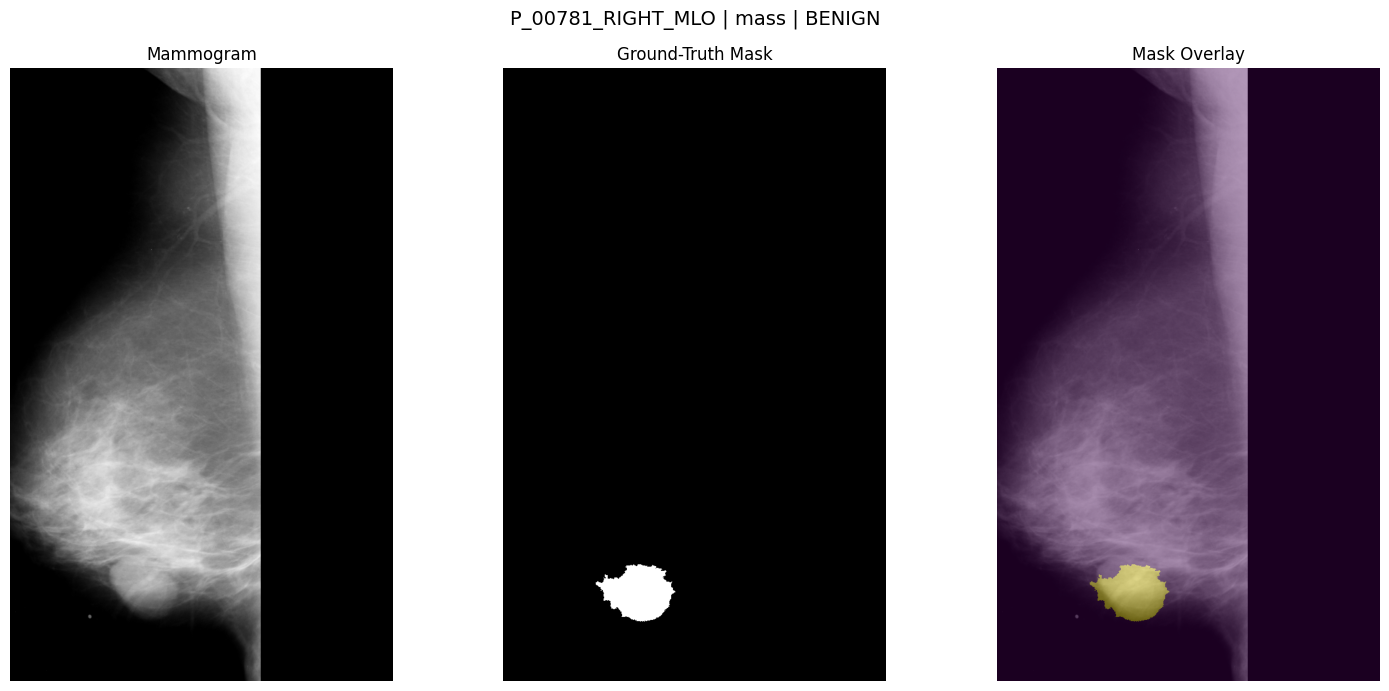

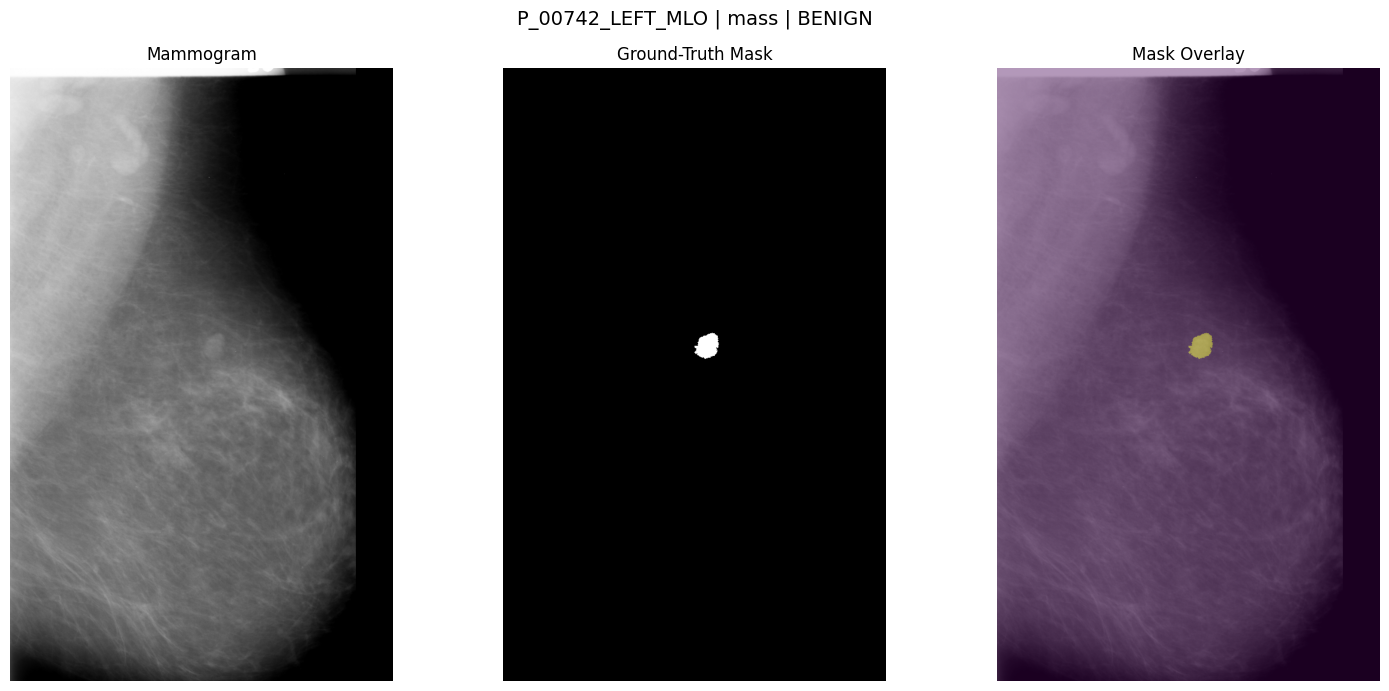

In [11]:
mass_examples = (
    all_df[
        all_df[
            "abnormality_type"
        ]
        .str.lower()
        .eq("mass")
    ]
    .sample(
        n=min(
            5,
            (
                all_df[
                    "abnormality_type"
                ]
                .str.lower()
                .eq("mass")
            ).sum(),
        ),
        random_state=SEED,
    )
)


for _, row in (
    mass_examples.iterrows()
):

    show_image_mask_pair(
        row=row,
        root_dir=PROJECT_ROOT,
    )

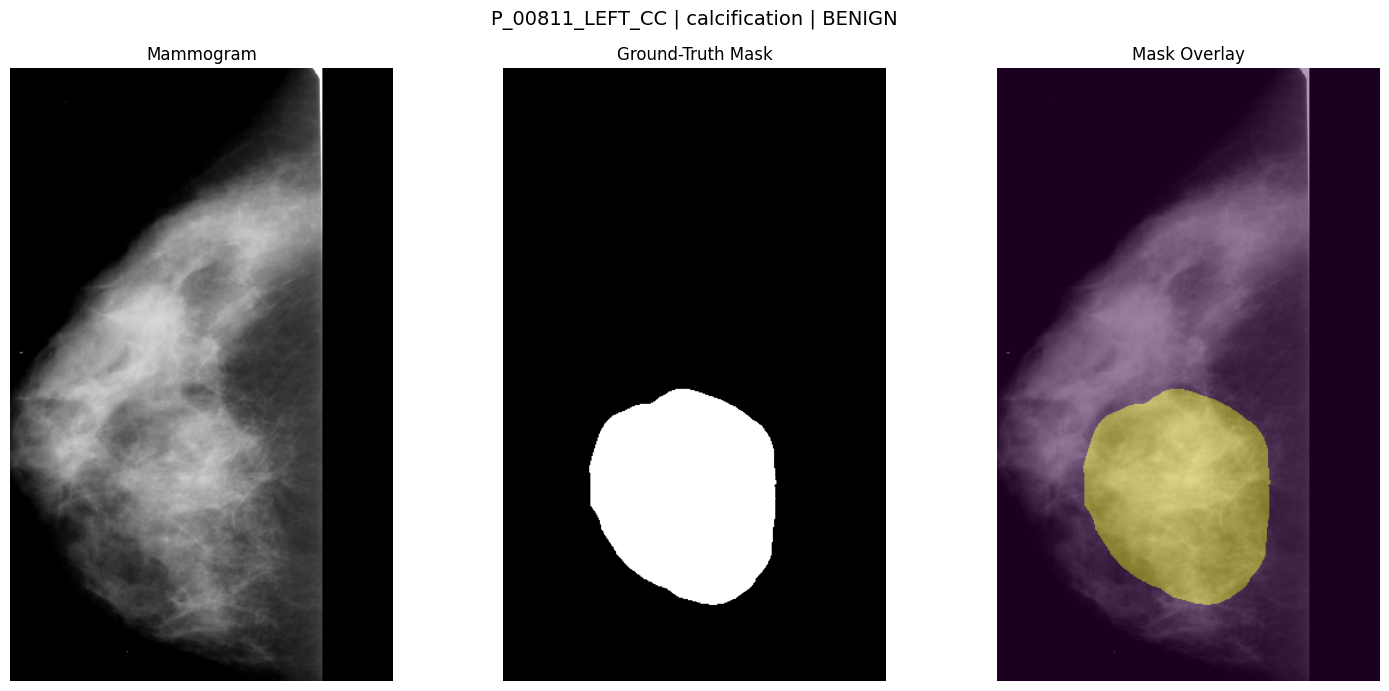

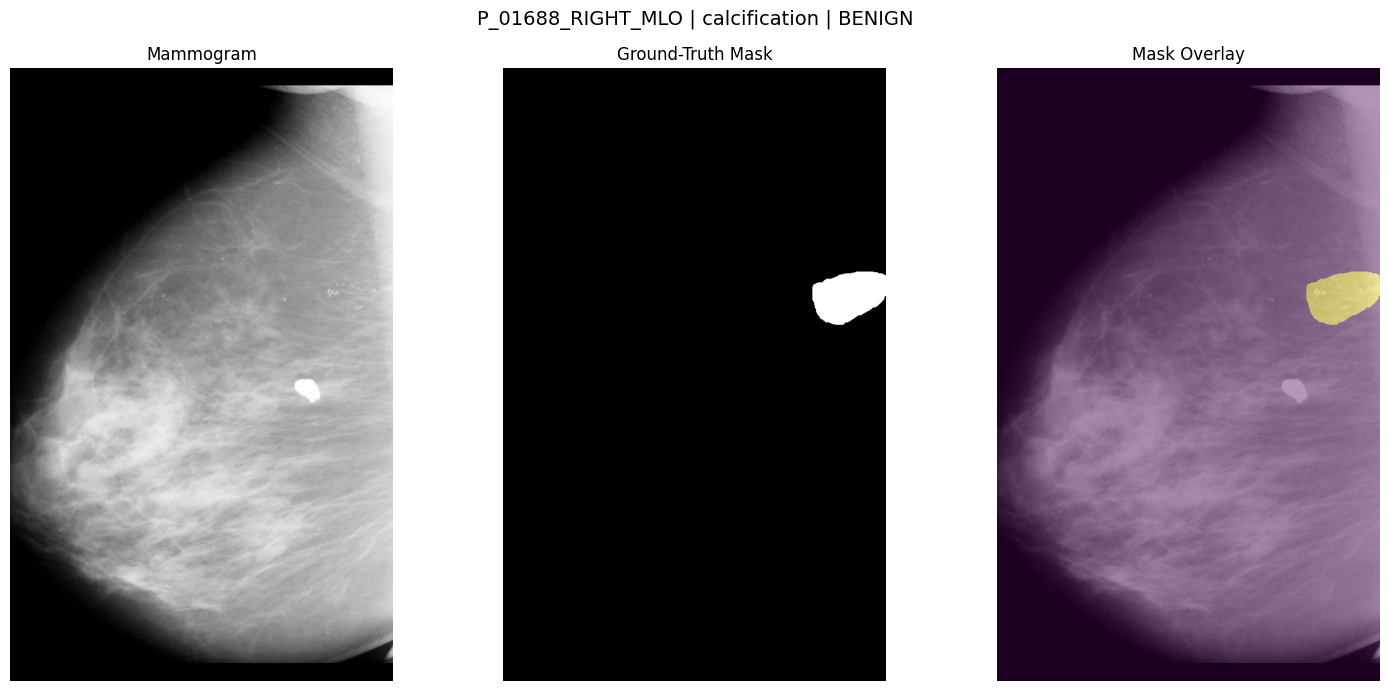

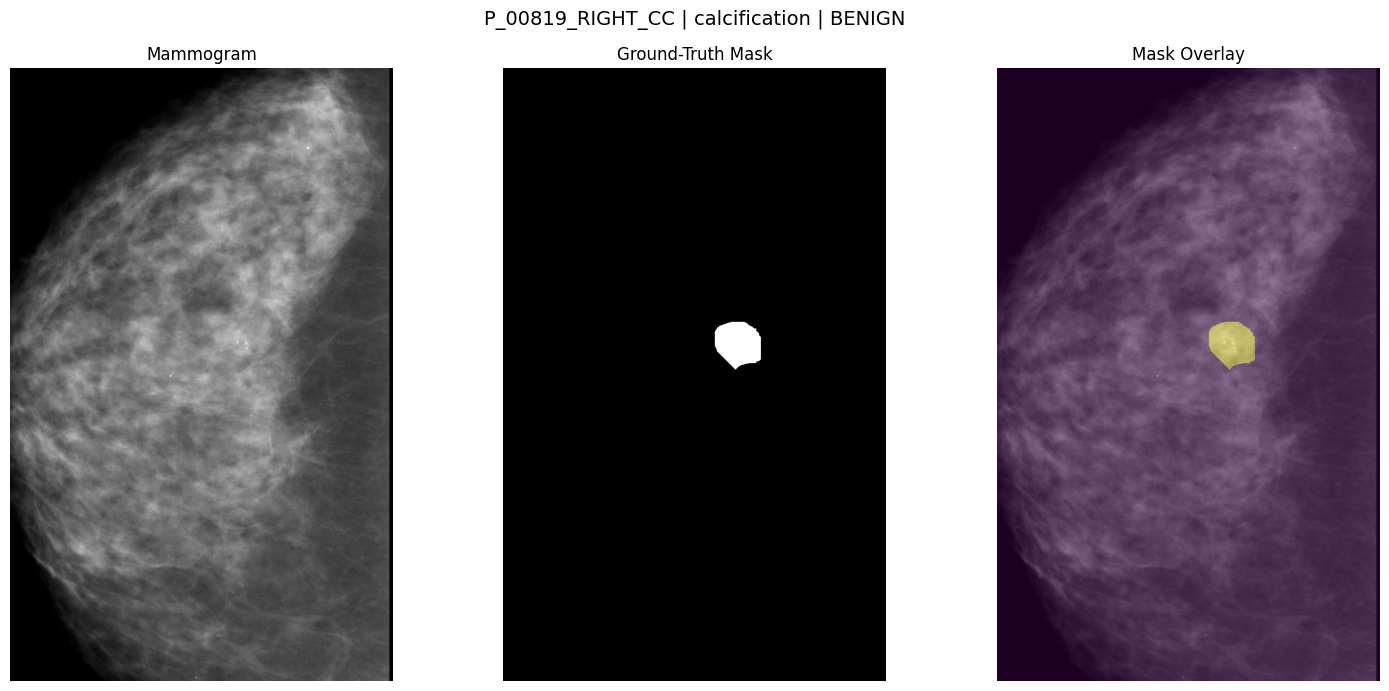

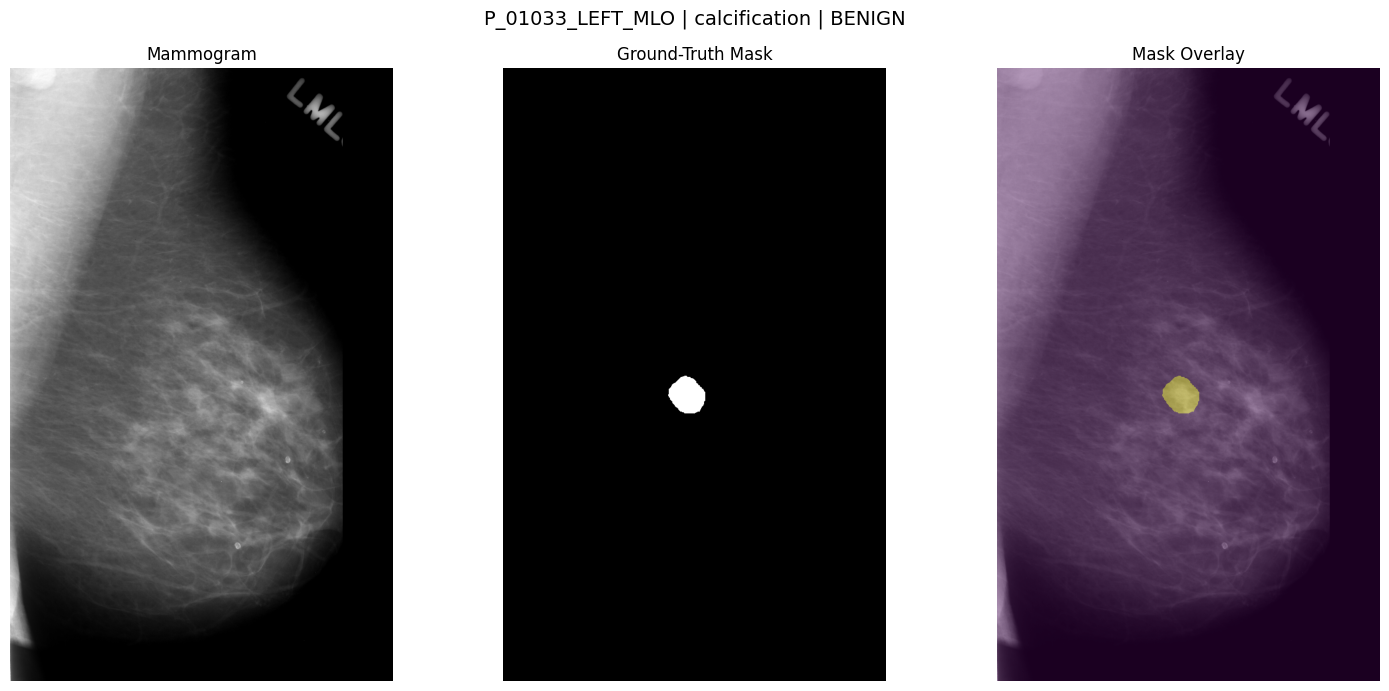

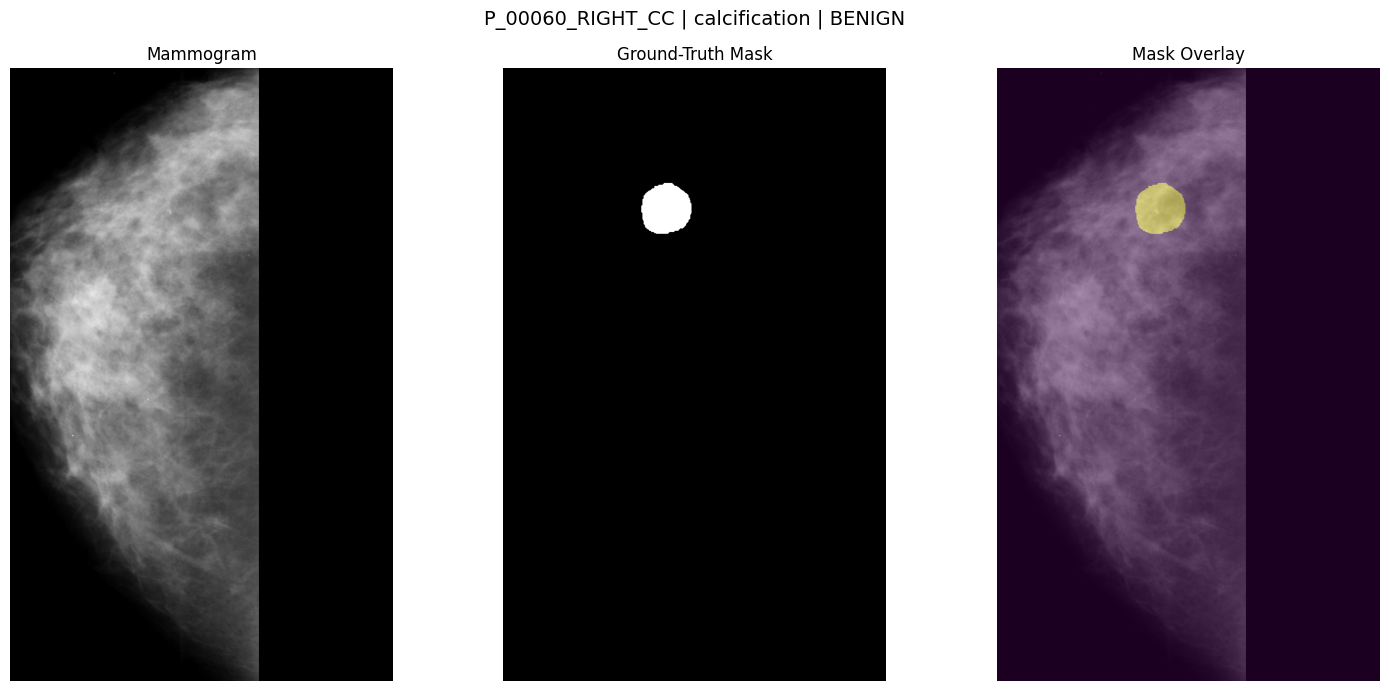

In [12]:
calc_examples = (
    all_df[
        all_df[
            "abnormality_type"
        ]
        .str.lower()
        .eq("calcification")
    ]
    .sample(
        n=min(
            5,
            (
                all_df[
                    "abnormality_type"
                ]
                .str.lower()
                .eq("calcification")
            ).sum(),
        ),
        random_state=SEED,
    )
)


for _, row in (
    calc_examples.iterrows()
):

    show_image_mask_pair(
        row=row,
        root_dir=PROJECT_ROOT,
    )

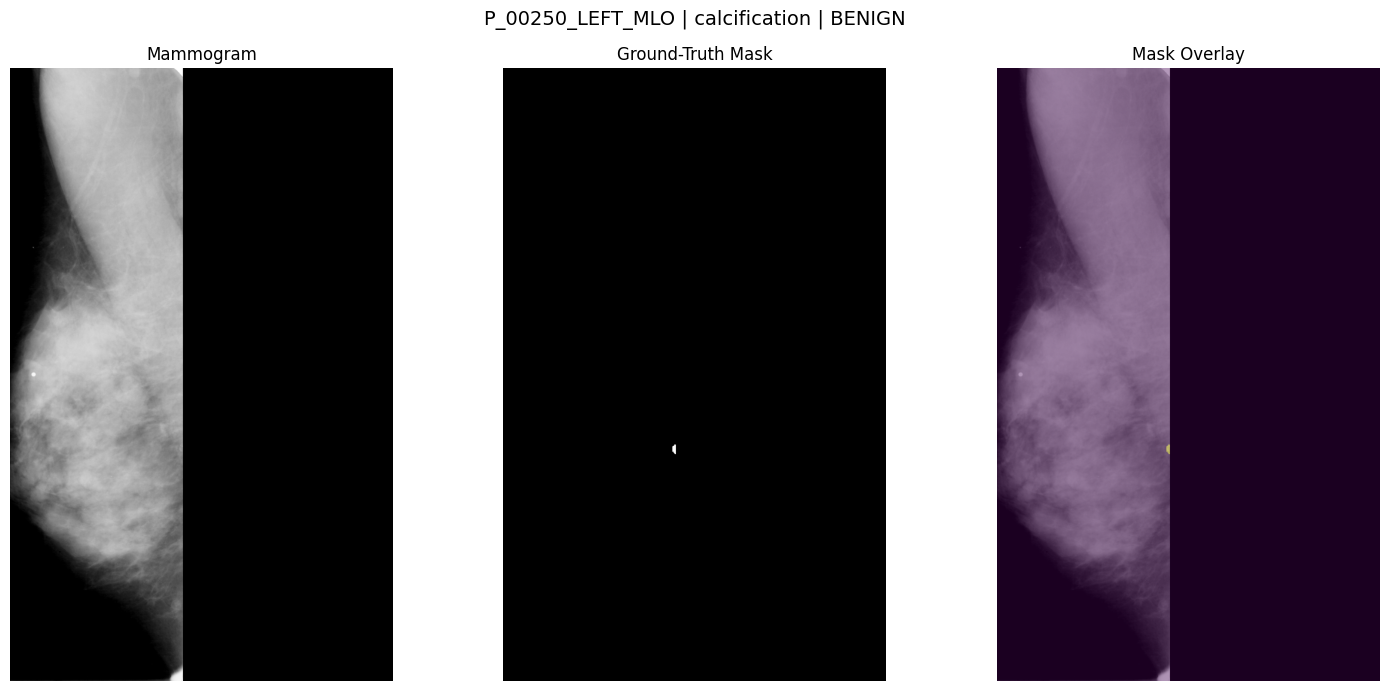

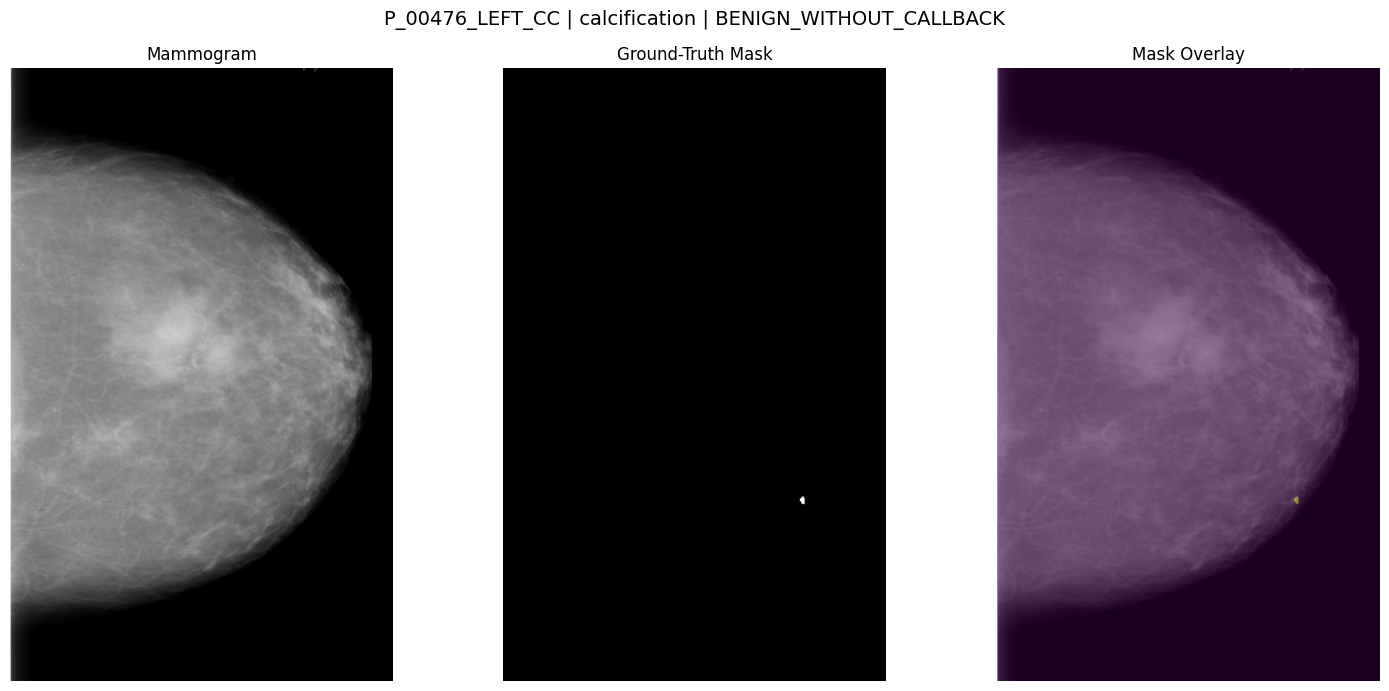

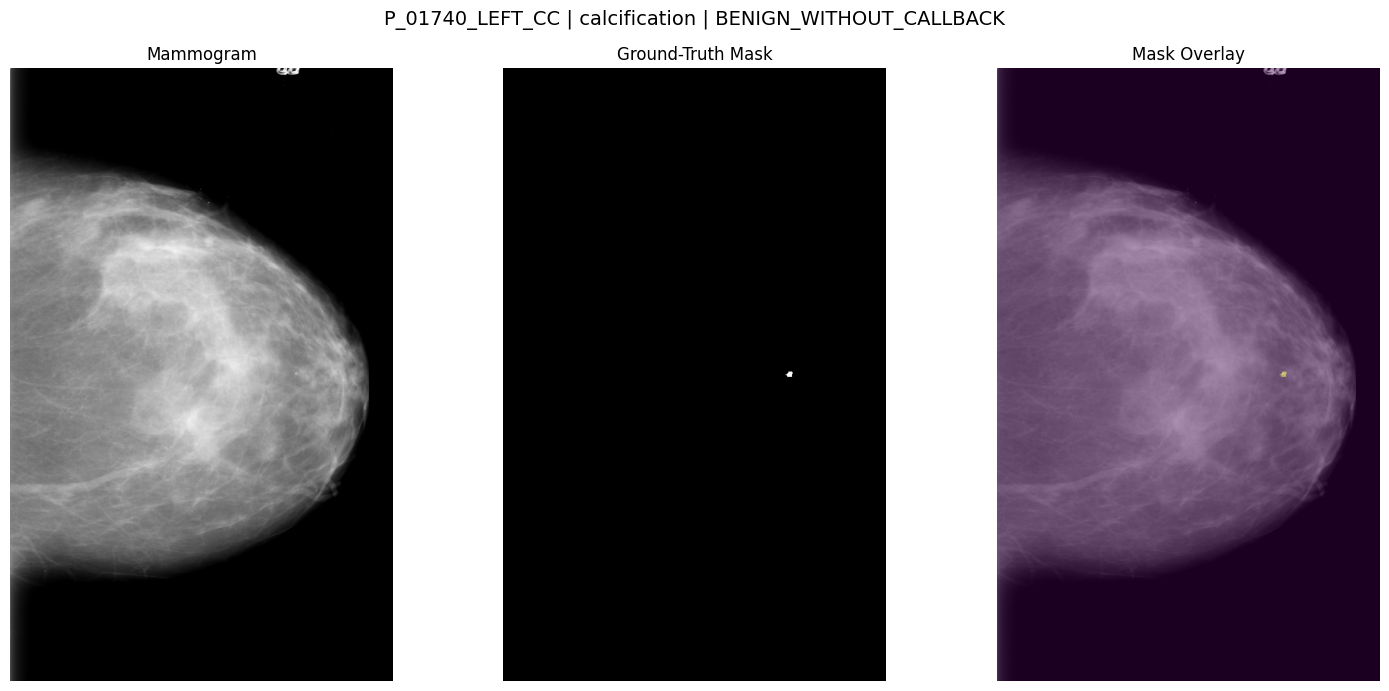

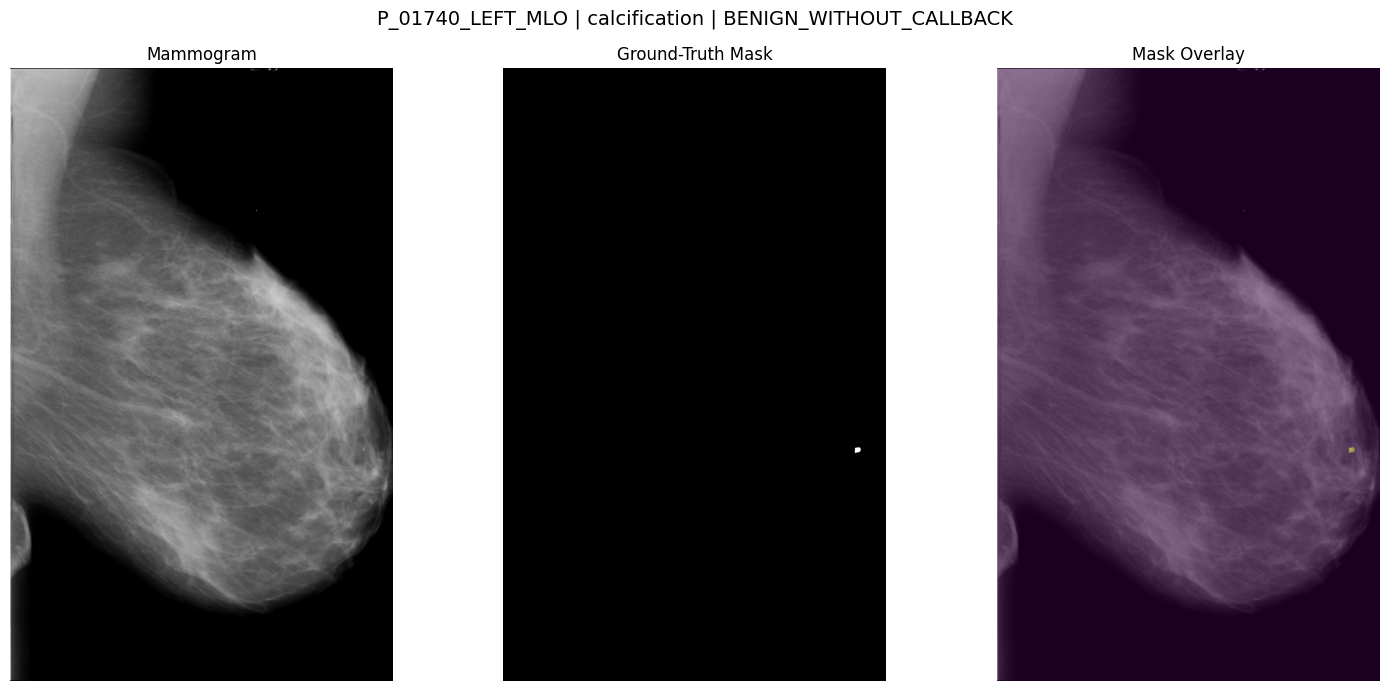

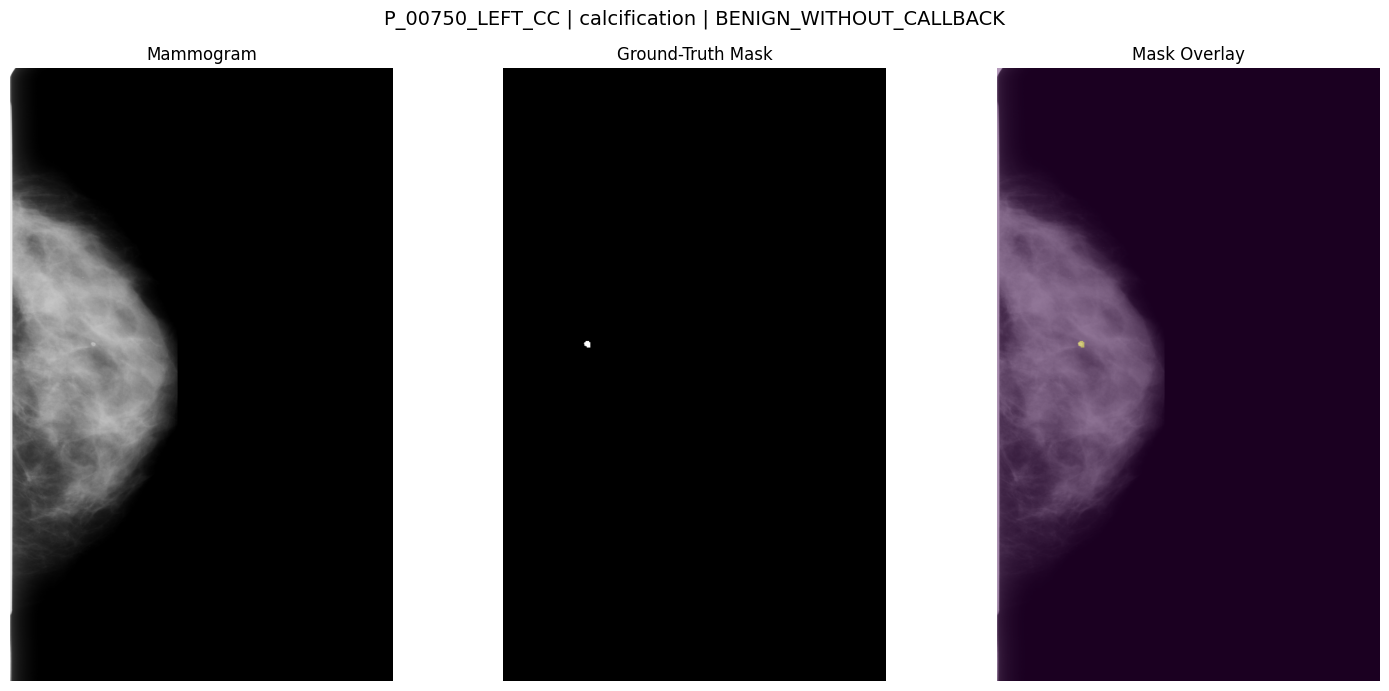

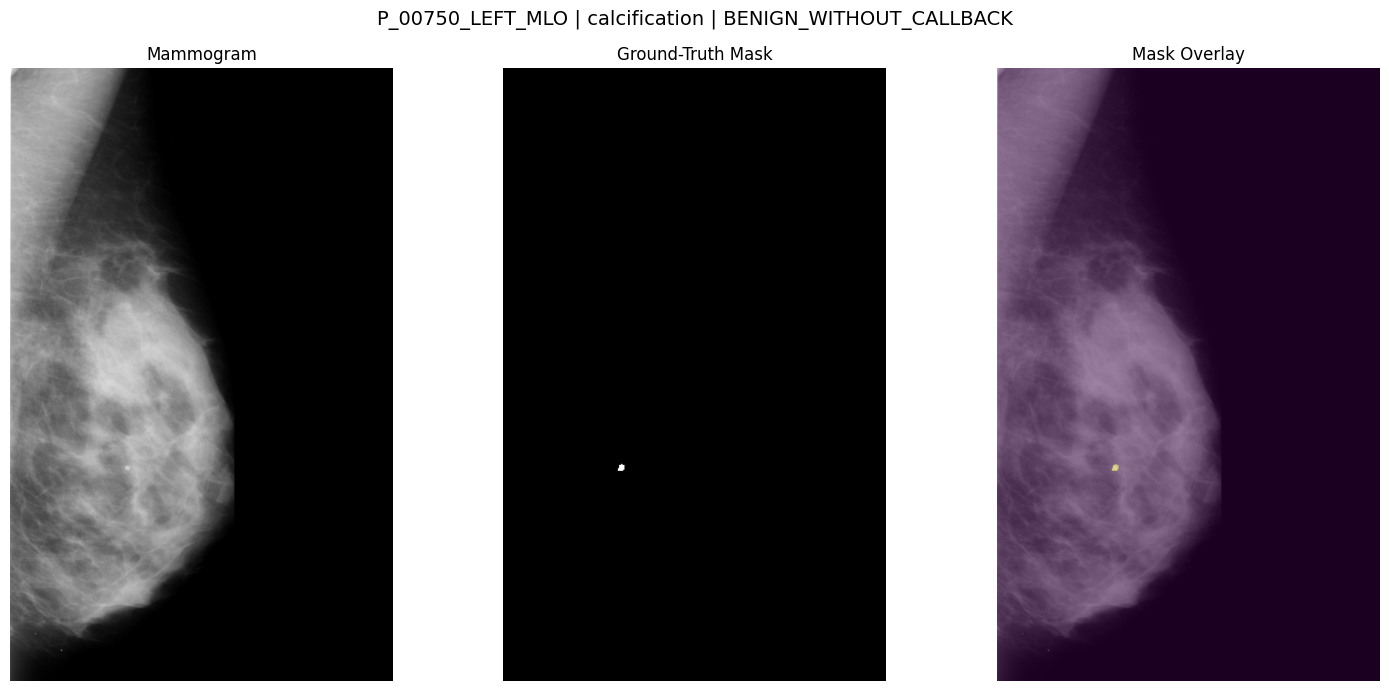

In [13]:
smallest_keys = (
    audit_df
    .sort_values(
        "mask_pixels"
    )
    .head(6)[
        "image_key"
    ]
    .tolist()
)


smallest_examples = (
    all_df[
        all_df[
            "image_key"
        ]
        .isin(
            smallest_keys
        )
    ]
)


for _, row in (
    smallest_examples.iterrows()
):

    show_image_mask_pair(
        row=row,
        root_dir=PROJECT_ROOT,
    )

In [14]:
train_patients = set(
    train_df["patient_id"]
)

val_patients = set(
    val_df["patient_id"]
)

test_patients = set(
    test_df["patient_id"]
)


assert train_patients.isdisjoint(
    val_patients
)

assert train_patients.isdisjoint(
    test_patients
)

assert val_patients.isdisjoint(
    test_patients
)


print(
    "Patient-level split integrity confirmed."
)

Patient-level split integrity confirmed.


In [15]:
segmentation_audit_summary = {
    "total_samples": int(
        len(audit_df)
    ),

    "train_samples": int(
        len(train_df)
    ),

    "validation_samples": int(
        len(val_df)
    ),

    "test_samples": int(
        len(test_df)
    ),

    "missing_images": int(
        (~audit_df["image_exists"]).sum()
    ),

    "missing_masks": int(
        (~audit_df["mask_exists"]).sum()
    ),

    "non_binary_masks": int(
        (~audit_df["mask_binary"]).sum()
    ),

    "empty_masks": int(
        (
            audit_df["mask_pixels"]
            == 0
        ).sum()
    ),

    "median_mask_fraction": float(
        audit_df[
            "mask_fraction"
        ].median()
    ),

    "minimum_mask_pixels": int(
        audit_df[
            "mask_pixels"
        ].min()
    ),

    "maximum_mask_pixels": int(
        audit_df[
            "mask_pixels"
        ].max()
    ),

    "resolution": [
        TARGET_HEIGHT,
        TARGET_WIDTH,
    ],
}


with open(
    OUTPUT_DIR
    / "segmentation_audit_summary.json",
    "w",
) as f:

    json.dump(
        segmentation_audit_summary,
        f,
        indent=2,
    )


print(
    json.dumps(
        segmentation_audit_summary,
        indent=2,
    )
)

{
  "total_samples": 2687,
  "train_samples": 1885,
  "validation_samples": 408,
  "test_samples": 394,
  "missing_images": 0,
  "missing_masks": 0,
  "non_binary_masks": 0,
  "empty_masks": 0,
  "median_mask_fraction": 0.005206298828125,
  "minimum_mask_pixels": 75,
  "maximum_mask_pixels": 382354,
  "resolution": [
    1024,
    640
  ]
}
